# taller PyTOUGH - Ejercicio 8
# Medio poroso-fracturado MINC

Ejercicio tomado de <a href="https://github.com/fguemar/tallerPyTOUGH">Taller PyTOUGH</a> por Fernando J. Guerrero, con el uso de biblioteca de funcioes <a href="https://github.com/acroucher/PyTOUGH">PyTOUGH</a> de Adrian Croucher. Uso bajo licencia <a href="https://creativecommons.org/licenses/by-nc-nd/4.0?ref=chooser-v1">Attribution-NonCommercial-NoDerivatives 4.0 International</a>

In [11]:
#==== PyTOUGH ==== 
#    geometry
from mulgrids import *
#   tough2 grids
from t2grids import *
# tough2 data files
from t2data import *
#  postprocesing
from t2listing import *
#================= 

# calls to system
import os
# Visualization Toolkit
from vtk import *
#from sympy import *
import math

#For plotting
import matplotlib.pyplot as plt

In [3]:
#en esta variable guardamos la dirección del directorio de trabajo
cwd=os.getcwd()

In [4]:
#mesh nodes
nodes=np.loadtxt(cwd+'/input/meshForAMESH.txt')
numnodes=nodes.shape[0]

# Este código crea un archivo 'in' para que AMESH construya una malla VORONOI
f=open(cwd+'/amesh/in','w')
f.write('locat\n')

tol=0.1
thck=305.
z0=0.
zc=z0+thck*0.5
i=1
for ly in range(1,2):
    zc=zc-thck
    for i in range(0,numnodes):
        xi=nodes[i][0]
        yi=nodes[i][1]
        f.write(format(i,"5d")+format(ly,"5d")+format(xi,"20.10e")+format(yi,"20.10e")+format(zc,"20.10e")+format(thck,"20.10e")+'\n')
        i=i+1
f.write('\n')

f.write('toler\n')
f.write(format(tol,"10.4f")+'\n')
f.write('\n')

#corners of the polygon - clockwise
f.write('bound\n')
f.write(format(0.,'9.3f')+' '+format(0.,'9.3f')+'\n')
f.write(format(353.553,'9.3f')+' '+format(353.553,'9.3f')+'\n')
f.write(format(707.10678,'9.3f')+' '+format(0.,'9.3f')+'\n')

f.close()


#ATENCIÓN: este comando ejecuta AMESH en mac - revisa cómo ejecurarlo en tu sistema
#os.system('cd amesh;./amesh6_osx')
#linux
#os.system('cd amesh;./amesh_linux')

In [5]:
#Importamos la malla a PyTOUGH
#use convention=2 for definition of GENER SL,NS - NS given by column name
#0 - 3 characters for column followed by 2 digits for layer
#1 - 3 characters for layer followed by 2 digits for column
#2 - 2 characters for layer followed by 3 digits for column
ameshgeo=mulgrid().from_amesh(input_filename=cwd+'/amesh/in', segment_filename=cwd+'/amesh/segmt', convention=1, node_tolerance=None, justify='r', chars=ascii_lowercase, spaces=True, block_order =None)
geo=ameshgeo[0]
geo.atmosphere_type=2
geo

43 nodes; 36 columns; 2 layers; 36 blocks; 0 wells
Naming convention: 1 (3 characters for layer, 2 digits for column)
Atmosphere type  : 2 (no atmosphere blocks)

In [6]:
geo.write_vtk(filename=cwd+'/mincModel_PView/mincModelm.vtu', arrays=None, wells=False, blockmap={}, surface_snap =0.1)

In [45]:
# Define TOUGH2 Grid
t2geo=t2grid().fromgeo(geo)

#Option 0 -> Homogeneous porous medium. Otherwise, Fractured porous medium
opt=0

if opt ==0:
    pomed=rocktype(name = 'pomed', density=2650., porosity=0.01, permeability = [6.e-15, 6.e-15, 6.e-15], conductivity=2.1, specific_heat = 1000.) 
    t2geo.add_rocktype(pomed)
    for blk in t2geo.blocklist:
        blk.rocktype=pomed
else:
    fract=rocktype(name = 'fract', density=2650., porosity=0.5, permeability = [6.e-15, 6.e-15, 6.e-15], conductivity=2.1, specific_heat = 1000.) 
    matrx=rocktype(name = 'Xract', density=2650., porosity=1.E-10, permeability = [0., 0., 0.], conductivity=2.1, specific_heat = 1000.)
    t2geo.add_rocktype(fract)
    t2geo.add_rocktype(matrx)


    for blk in t2geo.blocklist:
        blk.rocktype=fract

    vol_fracs=[.02,.08,.20,.35,.35]
    #MINC to all grid blocks
    t2geo.minc(vol_fracs, spacing=50., num_fracture_planes=3, blocks=None, 
               matrix_blockname=None, minc_rockname=None, proximity=None, 
               atmos_volume=1.e25, incon=None, fracture_connection_distance =0.)   
    
dat=t2data() 

#------------- EOS1 -------------
dat.grid=t2geo 
dat.title='# TOUGH2 - Sample problem 4'
dat.multi['num_components']=1
dat.multi['num_equations']=2 
dat.multi['num_phases']=2
dat.multi['num_secondary_parameters']=6
#--------------TIMES-------------
#dat.output_times['num_times_specified']=3
#dat.output_times['time']=[0.,1.57788E8,7.88940E8]

#--------------PARAM-------------
dat.parameter['max_iterations']=8   
dat.parameter['newton_weight']=1.    
#      ...      Output     ...
dat.parameter['print_level']=1 
dat.parameter['max_timesteps']=99 
dat.parameter['print_interval']=1
#      ---      MOP     ---
dat.parameter['option'][1]=1   
dat.parameter['option'][5]=0    
dat.parameter['option'][16]=4   
dat.parameter['option'][21]=2    
dat.parameter['relative_error']=1.E-5 
#      ...        ...
dat.parameter['tstart']=0. 
#..........................
dat.parameter['const_timestep']=1. 
dat.parameter['max_timestep']=(3600.*24.*365.)*1.  
#dat.parameter['gravity']=9.81  

dat.start=True 
dat.parameter['default_incons']=[300.,0.01]
#--------------RPCAP-------------
dat.relative_permeability['type']=3
dat.relative_permeability['parameters']=[0.30,0.05]
dat.capillarity['type']=1
dat.capillarity['parameters']=[0.,1.]
#===============================================

wll_inj = t2generator(name ='INJ00', block = '  a 1', type ='MASS', gx = 1.75, ex = 5.0E5)
wll_prd = t2generator(name ='PRO00', block = '  a11', type ='MASS', gx = -1.75)
dat.add_generator(wll_inj); dat.add_generator(wll_prd)

nyears=36.52
yrsec=3600.*24.*365.
dat.parameter['tstop']=yrsec*nyears 

dat.write('flow.inp')

In [41]:
#Análisis de resultados - crea un objeto t2listing a partir del archivo flow.out
lst = t2listing('flow.out')

#posiciónate en la última tabla de la serie de tiempo
lst.last()
#imprime qué tiempo es - ¿correspode con el tiempo de simulación esperado?
print(lst.time/(3600*24*365))

#imprime la tabla de resultados del tiempo en el que 'last'
df=lst.element.DataFrame
df
#----------

36.529680365296805


,row,P,T,SG,SW,X1,X2,PCAP,DG,DW
0,a 1,9441900.0,118.105,0.000000,1.000000,1.0,0.0,0.0,1.06004,949.023
1,a 2,8966550.0,128.720,0.000000,1.000000,1.0,0.0,0.0,1.44375,940.215
2,a 3,8774700.0,181.520,0.000000,1.000000,1.0,0.0,0.0,5.33439,890.522
3,a 4,8692440.0,247.984,0.000000,1.000000,1.0,0.0,0.0,19.29570,807.616
4,a 5,8642080.0,283.706,0.000000,1.000000,1.0,0.0,0.0,35.29500,747.084
5,a 6,8598600.0,295.926,0.000000,1.000000,1.0,0.0,0.0,43.18540,721.543
6,a 7,8552190.0,299.074,0.000000,1.000000,1.0,0.0,0.0,45.49020,714.287
7,a 8,8494280.0,299.183,0.140660,0.859340,1.0,0.0,0.0,45.57240,713.903
8,a 9,8361380.0,298.069,0.176365,0.823635,1.0,0.0,0.0,44.74070,716.181
9,a10,8109820.0,295.921,0.202564,0.797436,1.0,0.0,0.0,43.18170,720.515


In [10]:
#Salida a Paraview
lst.write_vtk(geo,cwd+'/mincModel_PView/smplP4.pvd', grid=t2geo, indices=None, flows=False, wells=False, start_time=0, time_unit='s', flux_matrix=None, blockmap = {}, surface_snap=0.1)

In [22]:
#MINC model
lst.last()
x1 = []
y1 = []
   
for cl in geo.columnlist[0:11]:
    blk=t2geo.block[geo.block_name(geo.layerlist[1].name, cl.name)]
    x1.append(blk.centre[0])
    y1.append(lst.element[blk.name]['T'])

In [42]:
#porous model
lst.last()
x2 = []
y2 = []
   
for cl in geo.columnlist[0:11]:
    blk=t2geo.block[geo.block_name(geo.layerlist[1].name, cl.name)]
    x2.append(blk.centre[0])
    y2.append(lst.element[blk.name]['T'])

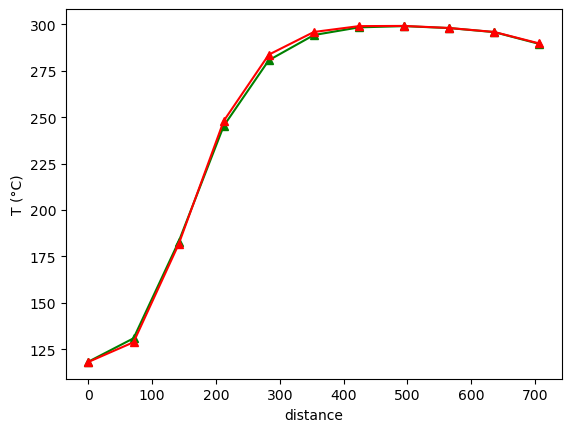

In [43]:
# plot
plt.plot(x1, y1, 'g-', x1, y1, 'g^',x2, y2, 'r-', x2, y2, 'r^')
plt.xlabel('distance')
plt.ylabel('T (°C)')

plt.show()